# All best-fit orbits in one plot


We use the best fit saved by each model notebook

In [1]:
import sys, copy, warnings, dataclasses
sys.path.insert(0, '..')                      # the package lives one level up
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np, torch
import matplotlib.pyplot as plt
%matplotlib inline

from ginn.core import S2Data, keplerian_prefit, LossConfig, train, objective, fit
from ginn.physics import METRICS
from ginn import analysis as an
from ginn import plotting as pl

data = S2Data.from_csv('../data/tab_gillessen_pos.csv', '../data/tab_gillessen_vr.csv')
print(data.summary())

Gillessen+2017: 145 astrometric epochs, 44 RVs, 1992.22-2016.53;  N_data = 334


In [2]:
import glob, os

files = sorted(glob.glob('results/*.pt'))
assert files, 'no results/*.pt found - run the model notebooks first'
res = {os.path.basename(f)[:-3]: torch.load(f, weights_only=False) for f in files}

ORDER = ['schwarzschild', 'reissner_nordstrom', 'hairy_horndeski', 'bardeen', 'jnw', 'yukawa']
res = {k: res[k] for k in ORDER if k in res}# remove for SdS

STYLES = [('#1f4e9c', '-'), ('#d1495b', '--'), ('#2a9d8f', '-.'), ('#e9a03b', ':'),
          ('#6a4c93', '--'), ('#8c564b', '-.'), ('#17becf', ':'), ('#7f7f7f', '-')]
style = {k: STYLES[i % len(STYLES)] for i, k in enumerate(res)}
LABEL_DEFAULT = {'schwarzschild': 'Schwarzschild', 'hairy_horndeski': 'Horndeski', 'yukawa': 'Yukawa', 'sds': 'SdS', 'reissner_nordstrom': 'RN', 'bardeen': 'Bardeen', 'jnw': 'JNW', 'ghs_dilaton': 'GHS dilaton'}
LABELS = {k: getattr(r['model'].metric, 'label', '') or LABEL_DEFAULT.get(k, k) for k, r in res.items()}
t = torch.linspace(1992.0, 2019.0, 5000)
pred = {}
with torch.no_grad():
    for k, r in res.items():
        ra, dec, v = r['model'].forward(t)
        pred[k] = (ra.numpy(), dec.numpy(), v.numpy())
for k, r in res.items():
    hair = ', '.join(f'{h} = {v:.3g} ± {s:.2g}' for h, (v, s) in r['hair'].items())
    print(f"{LABELS[k]:20s} chi2 = {an.chi2_parts(r['model'], data)['total']:8.2f}   {hair}")

Schwarzschild        chi2 =   290.00   
RN                   chi2 =   290.01   Q = 0.12 ± 2.2
Horndeski            chi2 =   288.44   q = 0.00486 ± 0.0038
Bardeen              chi2 =   290.01   g_b = 0.508 ± 57
JNW                  chi2 =   290.01   q_jnw = -3.66 ± 1.2e+02
Yukawa               chi2 =   287.88   delta = 0.0205 ± 0.014, log10_lambda = 3 ± 0


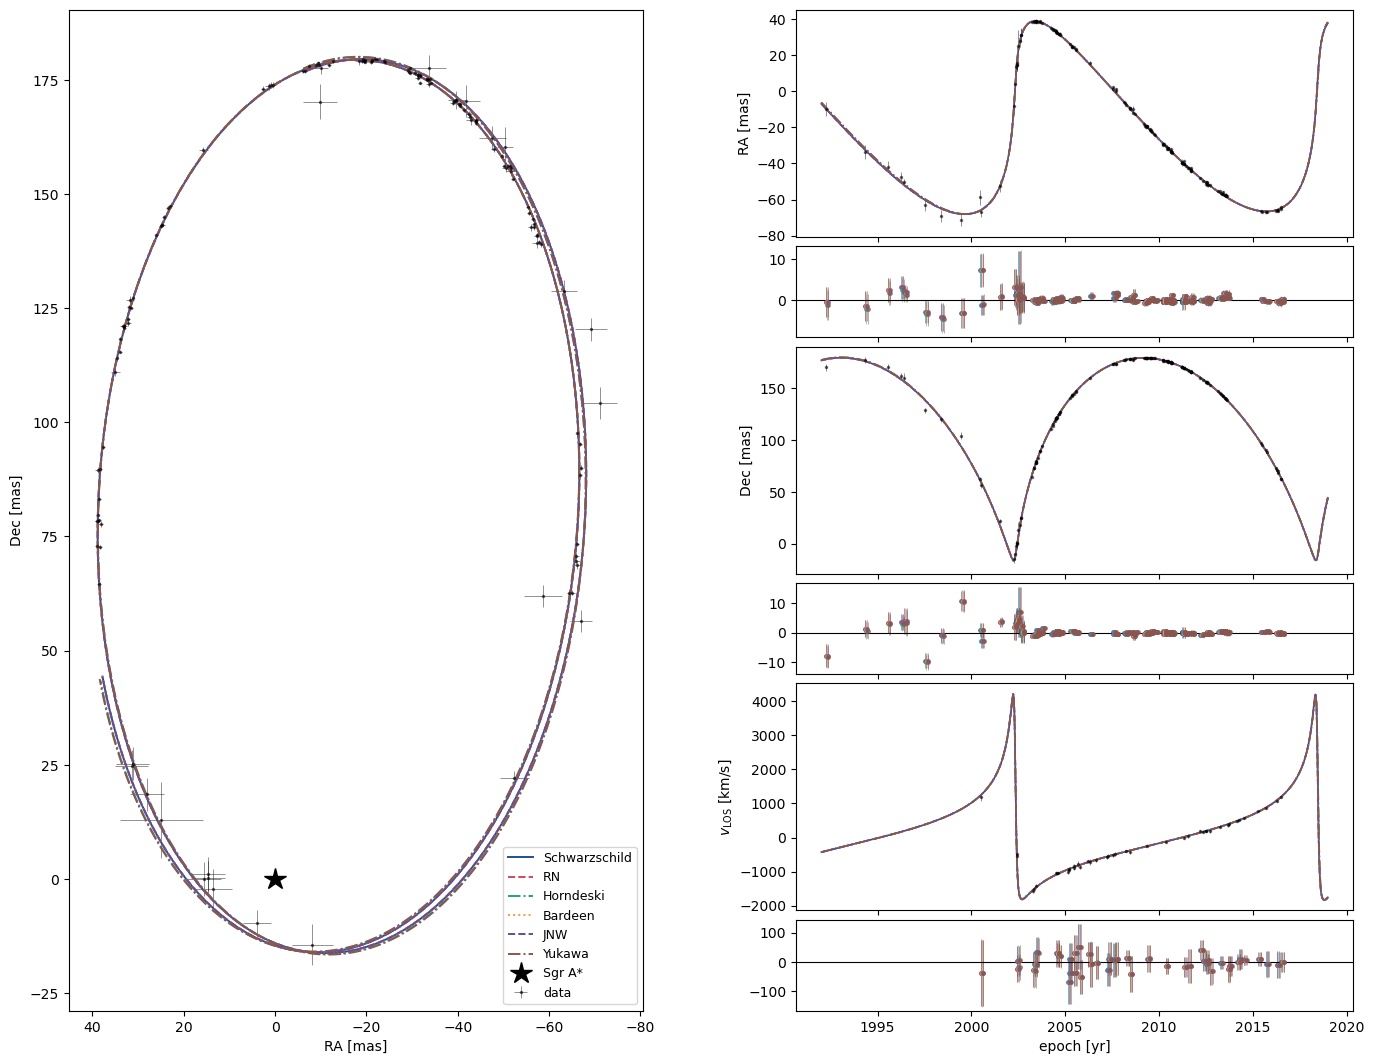

In [3]:
with torch.no_grad():                            # model values at the data epochs (residuals)
    dpred = {k: [x.numpy() for x in r['model'].predict_data(data)] for k, r in res.items()}
fig = plt.figure(figsize=(17, 13))
gs = fig.add_gridspec(6, 2, width_ratios=[1.15, 1], height_ratios=[3, 1.2, 3, 1.2, 3, 1.2], hspace=0.06)
ax = fig.add_subplot(gs[:, 0])
ax.errorbar(data.ra, data.dec, xerr=data.ra_e, yerr=data.dec_e, fmt='.', color='k', ms=3, alpha=0.5, lw=0.6, label='data')
for k, (ra, dec, v) in pred.items():
    c, ls = style[k]; ax.plot(ra, dec, color=c, ls=ls, lw=1.4, label=LABELS[k])
ax.plot(0, 0, marker='*', color='k', ms=16, ls='none', label='Sgr A*')
ax.invert_xaxis(); ax.set_aspect('equal')
ax.set_xlabel('RA [mas]'); ax.set_ylabel('Dec [mas]'); ax.legend(fontsize=9)
tt = t.numpy()
rows = [(0, 'RA [mas]', data.t_pos, data.ra, data.ra_e), (1, 'Dec [mas]', data.t_pos, data.dec, data.dec_e),
        (2, r'$v_{\rm LOS}$ [km/s]', data.t_rv, data.vlos, data.vlos_e)]
for row, (i, lab, td, y, ye) in enumerate(rows):
    a = fig.add_subplot(gs[2 * row, 1]); b = fig.add_subplot(gs[2 * row + 1, 1], sharex=a)
    a.errorbar(td, y, ye, fmt='.', color='k', ms=3, alpha=0.5, lw=0.6)
    for k, p in pred.items():
        c, ls = style[k]; a.plot(tt, p[i], color=c, ls=ls, lw=1.2)
    tdn, yn, yen = td.numpy(), y.numpy(), ye.numpy()
    for j, (k, dp) in enumerate(dpred.items()):
        c, ls = style[k]
        b.errorbar(tdn + 0.03 * j, yn - dp[i], yen, fmt='o', color=c, ms=2.5, lw=0.5, alpha=0.7)
    b.axhline(0, color='k', lw=0.8)
    a.set_ylabel(lab)#; b.set_ylabel('data −\nmodel')
    a.tick_params(labelbottom=False)
    if row < 2: b.tick_params(labelbottom=False)
b.set_xlabel('epoch [yr]'); plt.savefig("allorbits.pdf")
plt.show()

## Zoom at pericenter

C:\Users\phys6\AppData\Local\Temp\ipykernel_14012\224666107.py:1: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  tp = float(next(iter(res.values()))['model'].physical()['t0'])


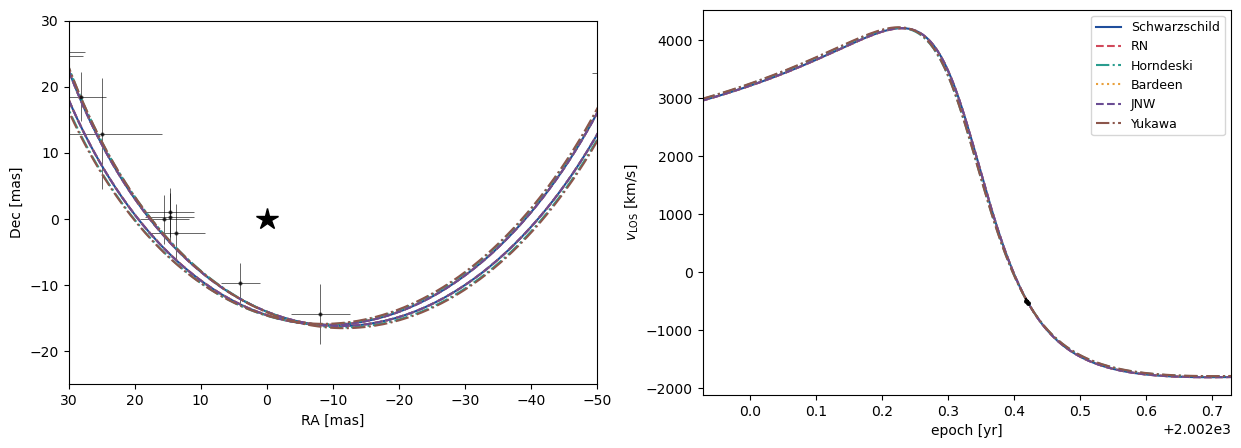

In [4]:
tp = float(next(iter(res.values()))['model'].physical()['t0'])
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
m_ = (tt > tp - 16.4) & (tt < tp + 16.4)
ax[0].errorbar(data.ra, data.dec, xerr=data.ra_e, yerr=data.dec_e, fmt='.', color='k', ms=4, alpha=0.6, lw=0.7)
for k, (ra, dec, v) in pred.items():
    c, ls = style[k]; ax[0].plot(ra[m_], dec[m_], color=c, ls=ls, lw=1.5, label=LABELS[k])
    ax[1].plot(tt[m_], v[m_], color=c, ls=ls, lw=1.5, label=LABELS[k])
ax[0].plot(0, 0, marker='*', color='k', ms=16, ls='none', label='Sgr A*')
ax[0].set_xlim(30, -50); ax[0].set_ylim(-25, 30); ax[0].set_aspect('equal')
ax[0].set_xlabel('RA [mas]'); ax[0].set_ylabel('Dec [mas]')
ax[1].errorbar(data.t_rv, data.vlos, data.vlos_e, fmt='.', color='k', ms=5)
ax[1].set_xlim(tp - 0.4, tp + 0.4); ax[1].set_xlabel('epoch [yr]'); ax[1].set_ylabel(r'$v_{\rm LOS}$ [km/s]')
ax[1].legend(fontsize=9); plt.show()

## Differences relative to Schwarzschild (grey band is the median data error)

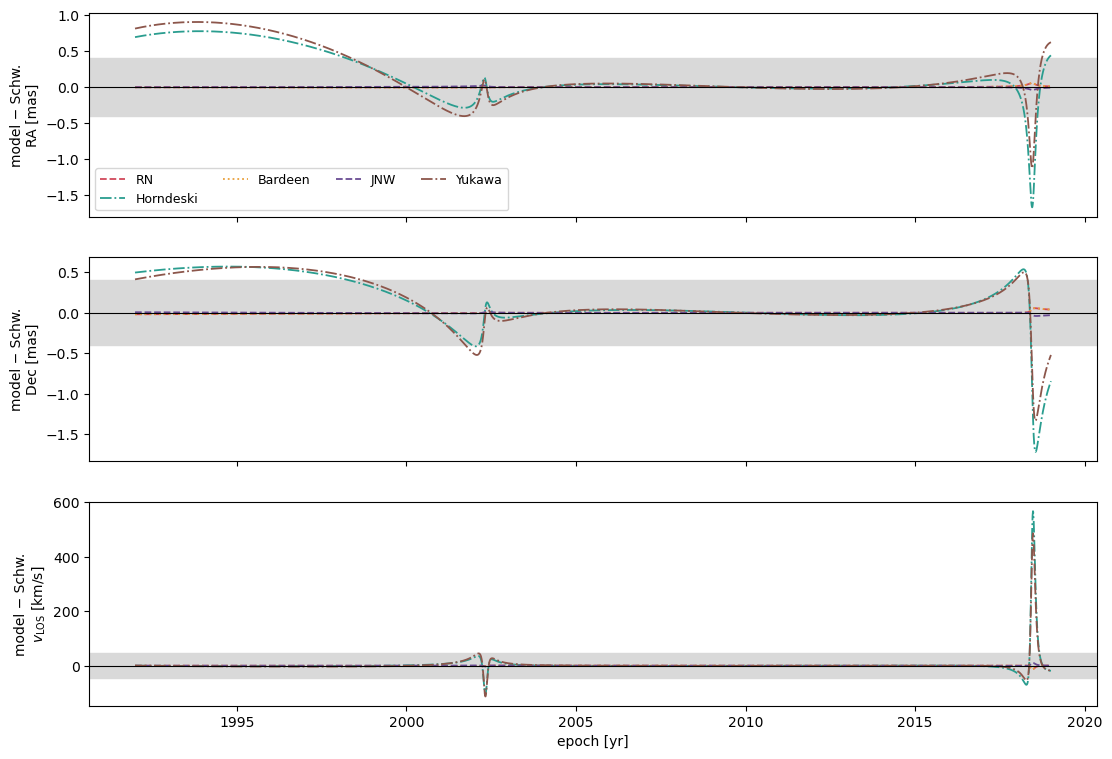

In [5]:
if 'schwarzschild' in pred:
    ref = pred['schwarzschild']
    fig, ax = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
    for i, (lab, err) in enumerate([('RA [mas]', float(data.ra_e.median())),
                                    ('Dec [mas]', float(data.dec_e.median())),
                                    (r'$v_{\rm LOS}$ [km/s]', float(data.vlos_e.median()))]):
        ax[i].axhspan(-err, err, color='0.85')
        for k, p in pred.items():
            if k == 'schwarzschild': continue
            c, ls = style[k]; ax[i].plot(tt, p[i] - ref[i], color=c, ls=ls, lw=1.3, label=LABELS[k])
        ax[i].axhline(0, color='k', lw=0.8); ax[i].set_ylabel('model − Schw.\n' + lab)
    ax[0].legend(fontsize=9, ncol=4); ax[-1].set_xlabel('epoch [yr]'); plt.show()
else:
    print('run 01_schwarzschild.ipynb first to see the differences')

## Compare between models
First we shows how much the mass and the distance of Sgr A* vary for every model,
Then we show the posterior of each hair parameter, with GR value as a dashed line.

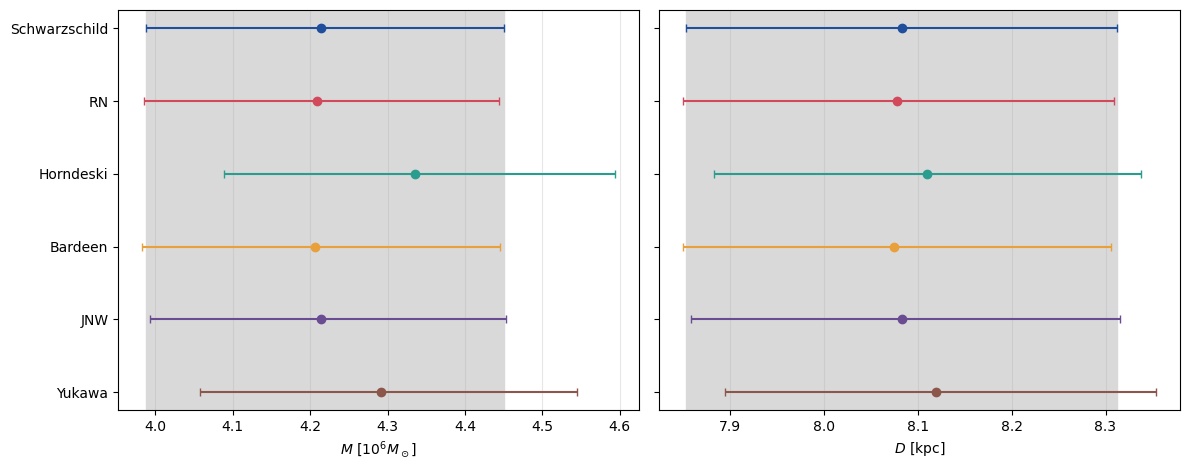

In [6]:
have = {k: r for k, r in res.items() if 'samples' in r}
missing = sorted(set(res) - set(have))
if missing:
    print('no samples stored yet for:', ', '.join(LABELS[k] for k in missing), '(re-run those notebooks)')

# Figure 1: M and R0 for every model
fig, ax = plt.subplots(1, 2, figsize=(12, 0.55 * len(have) + 1.5), sharey=True)
for j, k in enumerate(have):
    S_ = have[k]['samples']
    for a_, key in zip(ax, ['M', 'D']):
        lo, med, hi = np.percentile(S_[key], [15.865, 50, 84.135])
        c, ls = style[k]
        a_.errorbar(med, j, xerr=[[med - lo], [hi - med]], fmt='o', color=c, capsize=3)
if 'schwarzschild' in have:
    for a_, key in zip(ax, ['M', 'D']):
        lo, hi = np.percentile(have['schwarzschild']['samples'][key], [15.865, 84.135])
        a_.axvspan(lo, hi, color='0.85', zorder=0)
ax[0].set_yticks(range(len(have))); ax[0].set_yticklabels([LABELS[k] for k in have])
ax[0].set_xlabel(r'$M\ [10^6 M_\odot]$'); ax[1].set_xlabel(r'$D$ [kpc]')
ax[0].invert_yaxis()
for a_ in ax: a_.grid(alpha=0.3, axis='x')
plt.tight_layout(); plt.show()

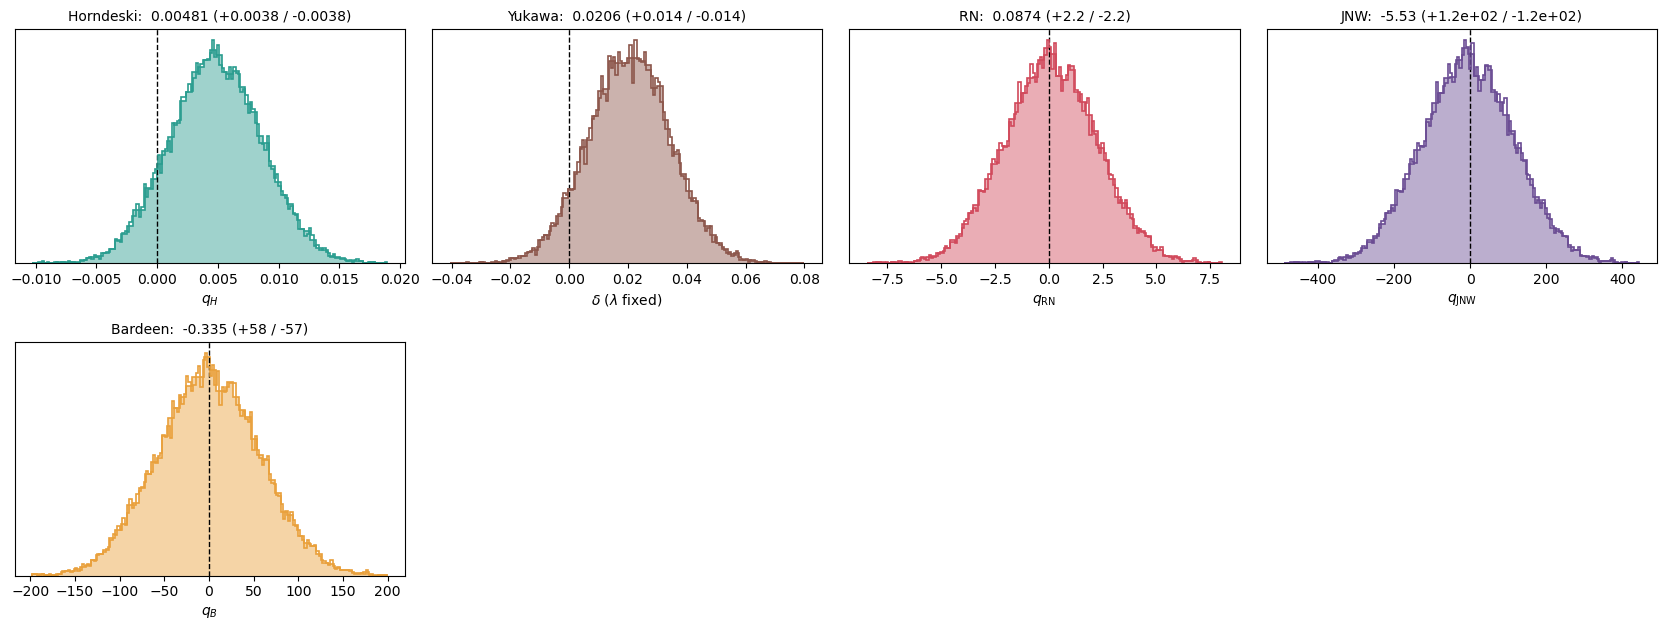

In [7]:
# Figure 2: one panel per hair parameter (posterior from the model's samples, GR value dashed)
HAIR = {'hairy_horndeski': ('q', r'$q_H$', 0.0), 'yukawa': ('delta', r'$\delta$ ($\lambda$ fixed)', 0.0), 
        'sds': ('log10_Lambda', r'$\log_{10}(\Lambda/{\rm m^{-2}})$', None),
        'reissner_nordstrom': ('Q', r'$q_{\rm RN}$', 0.0), 'ghs_dilaton': ('a_dil', r'$b/M$', 0.0),
        'jnw': ('q_jnw', r'$q_{\rm JNW}$', 0.0), 'bardeen': ('g_b', r'$q_B$', 0.0)}
panels = [k for k in HAIR if k in have and HAIR[k][0] in have[k]['samples']]
if panels:
    ncol = min(4, len(panels)); nrow = int(np.ceil(len(panels) / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.2 * nrow), squeeze=False)
    for a_, k in zip(axs.ravel(), panels):
        key, xl, gr = HAIR[k]
        x = have[k]['samples'][key]
        a_.hist(x, bins=60, density=True, histtype='stepfilled', color=style[k][0], alpha=0.45)
        a_.hist(x, bins=60, density=True, histtype='step', color=style[k][0], lw=1.2)
        lo, med, hi = np.percentile(x, [15.865, 50, 84.135])
        if gr is not None:
            a_.axvline(gr, color='k', ls='--', lw=1)
            a_.set_title(f'{LABELS[k]}:  {med:.3g} (+{hi - med:.2g} / -{med - lo:.2g})', fontsize=10)
        else:
            a_.set_title(f'{LABELS[k]}:  95% upper limit {np.percentile(x, 95):.2f}', fontsize=10)
        a_.set_xlabel(xl); a_.set_yticks([])
        rng = (-70, -35) if k == 'sds' else None
        #a_.hist(x, bins=150, range=rng, density=True, histtype='stepfilled', color=style[k][0], alpha=0.45)
        a_.hist(x, bins=150, range=rng, density=True, histtype='step', color=style[k][0], lw=1.2)
    for a_ in axs.ravel()[len(panels):]:
        a_.axis('off')
    plt.tight_layout(); plt.show()

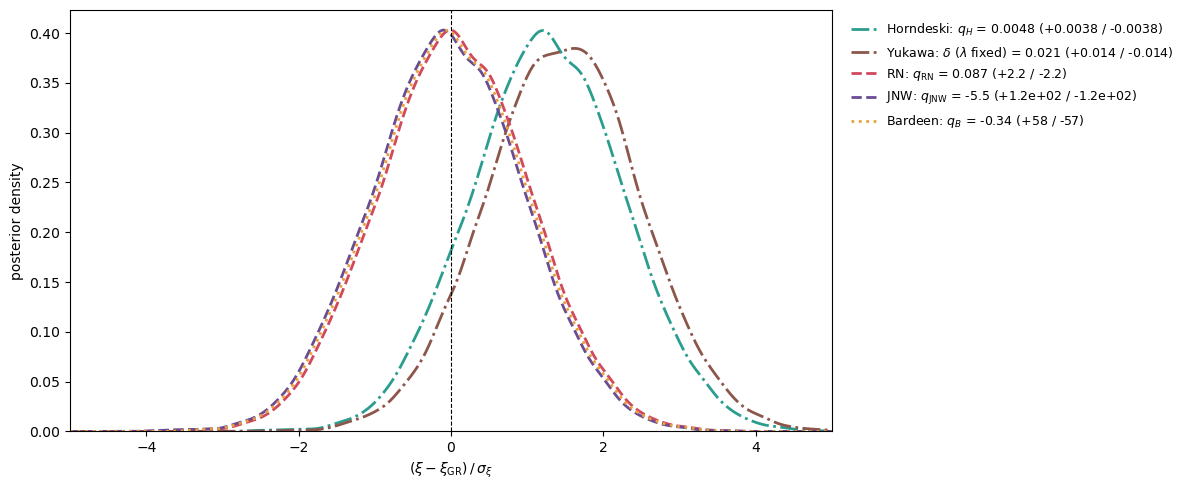

In [8]:
from scipy.stats import gaussian_kde
fig, ax = plt.subplots(figsize=(12, 5))
zz = np.linspace(-5, 5, 500)
for k in panels:
    key, xl, gr = HAIR[k]
    if gr is None:
        continue
    x = np.asarray(have[k]['samples'][key])
    lo, med, hi = np.percentile(x, [15.865, 50, 84.135])
    z = (x - gr) / (0.5 * (hi - lo))
    z = z[np.random.default_rng(0).choice(len(z), min(len(z), 20000), replace=False)]
    c, ls = style[k]
    ax.plot(zz, gaussian_kde(z)(zz), color=c, ls=ls, lw=2,
            label=f"{LABELS[k]}: {xl} = {med:.2g} (+{hi - med:.2g} / -{med - lo:.2g})")
ax.axvline(0, color='k', lw=0.8, ls='--')
ax.set_xlabel(r'$(\xi-\xi_{\rm GR})\,/\,\sigma_\xi$')
ax.set_ylabel('posterior density')
ax.set_xlim(-5, 5); ax.set_ylim(0, None)
ax.legend(fontsize=9, loc='upper left', bbox_to_anchor=(1.01, 1.0), frameon=False)
plt.tight_layout(); plt.show()

model               dchi2  ln Occam  dln vol    ln B   evidence
RN                   0.00     -2.92     0.00   -2.92   moderate for Schwarzschild
Horndeski           -1.57     -2.35     0.01   -1.56   weak for Schwarzschild
Bardeen              0.00     -1.02     0.00   -1.02   weak for Schwarzschild
JNW                  0.00     -1.37     0.00   -1.37   weak for Schwarzschild
Yukawa              -2.13     -3.35     0.02   -2.26   weak for Schwarzschild

ln B is relative to Schwarzschild (> 0 favours the model). The Occam term scales as -ln(prior width):
halving a hair prior raises ln B by ln 2 = 0.69, so the numbers are only meaningful together with the priors.


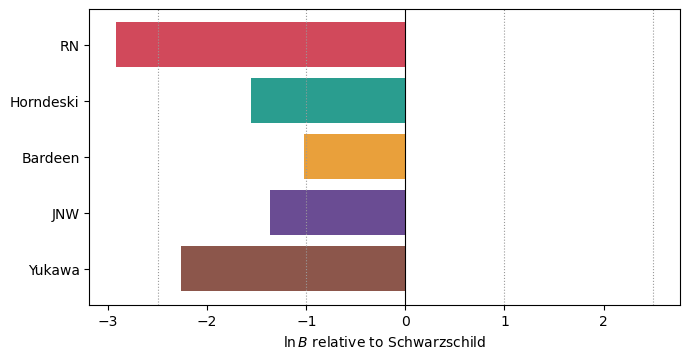

In [9]:
rows = []
ev_ref = res.get('schwarzschild', {}).get('evidence')
for k, r in res.items():
    if k == 'schwarzschild':
        continue
    if 'bayes' in r:
        rows.append((k, r['bayes']))
    elif 'evidence' in r and ev_ref is not None:
        rows.append((k, an.bayes_factor(r['evidence'], ev_ref)))
    else:
        print(f'{LABELS[k]}: no evidence stored (re-run its notebook)')
print(f"{'model':16s} {'dchi2':>8s} {'ln Occam':>9s} {'dln vol':>8s} {'ln B':>7s}   evidence")
for k, bf in rows:
    print(f"{LABELS[k]:16s} {bf['dchi2']:8.2f} {bf['ln_occam']:9.2f} {bf['dln_vol']:8.2f} {bf['lnB']:7.2f}   {bf['verdict']}")
print("\nln B is relative to Schwarzschild (> 0 favours the model). The Occam term scales as -ln(prior width):\n"
      "halving a hair prior raises ln B by ln 2 = 0.69, so the numbers are only meaningful together with the priors.")
if rows:
    fig, ax = plt.subplots(figsize=(7, 0.5 * len(rows) + 1.2))
    ax.barh([LABELS[k] for k, _ in rows], [bf['lnB'] for _, bf in rows], color=[style[k][0] for k, _ in rows])
    for x0 in (-2.5, -1, 1, 2.5):
        ax.axvline(x0, color='0.6', ls=':', lw=0.8)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel(r'$\ln B$ relative to Schwarzschild'); ax.invert_yaxis()
    plt.tight_layout(); plt.show()